# **Import libraries and download dataset**

In [1]:
%pip -q install kagglehub

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

path = kagglehub.dataset_download("yasserh/uber-fares-dataset")
import glob, os
df = pd.read_csv(glob.glob(os.path.join(path, "*.csv"))[0])

print(df.head())

Using Colab cache for faster access to the 'uber-fares-dataset' dataset.
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325               

# Preprocess the dataset

In [2]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
df = df.dropna()

df = df[
    (df["fare_amount"].between(1, 200)) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["dropoff_latitude"].between(40, 42)) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_longitude"].between(-75, -72))
].copy()

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)
df = df.dropna(subset=["pickup_datetime"])

# Calculate distance using Haversine formula
lat1 = np.radians(df["pickup_latitude"])
lat2 = np.radians(df["dropoff_latitude"])
lon1 = np.radians(df["pickup_longitude"])
lon2 = np.radians(df["dropoff_longitude"])

a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
df["distance"] = 6371 * 2 * np.arcsin(np.sqrt(a))

df = df[df["distance"].between(0.1, 100)].copy()

df["hour"] = df["pickup_datetime"].dt.hour

print("Cleaned dataset:", df.shape)

Cleaned dataset: (191893, 9)


# Train both models

In [3]:
X = df[["distance", "passenger_count", "hour"]]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr = LinearRegression()
lr.fit(X_train, y_train)
p1 = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
p2 = rf.predict(X_test)

print("Both models trained successfully!")

Both models trained successfully!


# Compare results


 Linear Regression
R2 Score: 0.735
RMSE: 4.952

 Random Forest
R2 Score: 0.777
RMSE: 4.544


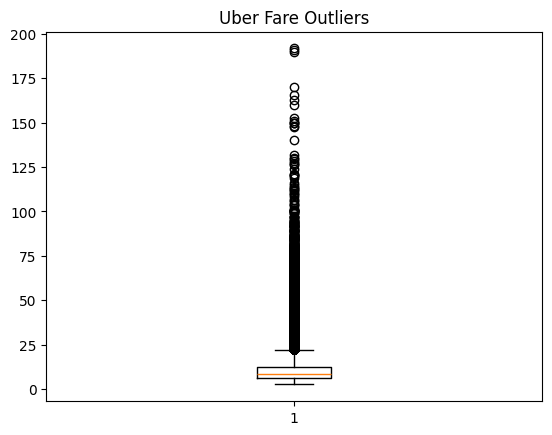

In [4]:
for name, pred in [
    ("Linear Regression", p1),
    ("Random Forest", p2)
]:
    print("\n", name)
    print("R2 Score:", round(r2_score(y_test, pred), 3))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))

# Outlier visualization
plt.boxplot(df["fare_amount"])
plt.title("Uber Fare Outliers")
plt.show()